# Task 1: Linear Regression Model (California Housing Dataset)

In [2]:
#Lib installation
import pandas as pd #pandas Lib Installed for Excel for Python
import numpy as np #numpy Lib Installed handles this heavy matrix math and arrays incredibly fast behind the scenes.
import matplotlib.pyplot as plt #core graphing library
import seaborn as sns #lib imported for making graph clean with less code
from sklearn.datasets import fetch_california_housing #standard California Housing dataset built right in
from sklearn.model_selection import train_test_split #It randomly slices your 20,000+ rows of housing data into two chunks: a large "Training" set (usually 80%) for your model to study and learn the patterns, and a hidden "Testing" set (20%) to test the model's accuracy on houses it has never seen before.
from sklearn.linear_model import LinearRegression #actual AI algorithm
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score #model's final report card

In [3]:
# 1. Download the dataset in a Pandas-friendly format
data = fetch_california_housing(as_frame=True)

# 2. Glue the 'features' (house stats) and the 'target' (house price) into one table
df = pd.concat([data.data, data.target.rename('MedHouseVal')], axis=1)

# 3. Print the first 5 rows to verify it loaded correctly
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
X = df.drop(columns='MedHouseVal') #takes your entire DataFrame (df) but literally drops the MedHouseVal (price) column. This leaves only the clues (income, age, rooms, etc.) for the model to look at.
y = df['MedHouseVal'] #takes only the MedHouseVal column.

In [5]:
#code in this part use for prevent AI to memorize the answers
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
#model part
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [8]:
mae = mean_absolute_error(y_test, y_pred)
# removed 'squared=False' and manually take the square root using ** 0.5 , because it giving the TypeError in next rmse code line
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.3f} RMSE: {rmse:.3f} R2: {r2:.3f}")

MAE: 0.533 RMSE: 0.746 R2: 0.576


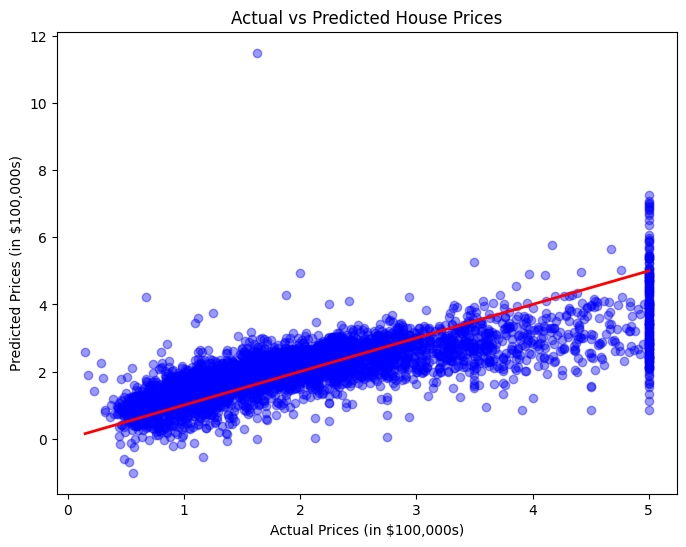

In [9]:
# Plotting the Actual vs Predicted prices
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.4, color='blue')
plt.xlabel("Actual Prices (in $100,000s)")
plt.ylabel("Predicted Prices (in $100,000s)")
plt.title("Actual vs Predicted House Prices")

# Drawing the perfect prediction line in red
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linewidth=2)
plt.show()